<!-- Progetto Pratica W12D4 - ToysGroup
In questo notebook vengono svolti tutti i task richiesti W12D4. -->


<!-- Task 1
Lista: Ordinata, mutabile, consente duplicati. Si accede tramite indice numerico `[i]`.
Tupla: Ordinata, immutabile, consente duplicati. Si accede tramite indice numerico `[i]`.
Set: Non ordinato, mutabile, contiene solo elementi unici (no duplicati). Non si accede tramite indice.
Dizionario: Struttura chiave-valore non ordinata, mutabile, chiavi uniche. Si accede tramite chiave `[chiave]`. -->


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Leggere products.csv e sales.json e convertirli con .to_dict(orient="records") in liste di dizionari
df_products = pd.read_csv('products.csv')
df_sales = pd.read_json('sales.json')
df_regions = pd.read_excel('regions.xlsx')

products_list = df_products.to_dict(orient="records")
sales_list = df_sales.to_dict(orient="records")

# Costruire regions come dizionario {RegionID: (State, SalesRegion)}
regions_dict = {
    row['RegionID']: (row['State'], row['SalesRegion'])
    for _, row in df_regions.iterrows()
}

# Set delle categorie
categories_set = set(df_products['Category'].dropna())

print(f"Numero prodotti in lista: {len(products_list)}")
print(f"Esempio dizionario regions: {list(regions_dict.items())[:2]}")
print(f"Set delle categorie: {categories_set}")

# 2. List comprehension per fascia di prezzo
# Bassa (<20€), Media (20€-60€), Alta (>60€)
for prod in products_list:
    price = prod.get('ListPrice', 0)
    if price < 20:
        prod['FasciaPrezzo'] = 'Bassa'
    elif price <= 60:
        prod['FasciaPrezzo'] = 'Media'
    else:
        prod['FasciaPrezzo'] = 'Alta'

# Mostra i primi 5 prodotti con fascia di prezzo
print("Primi 5 prodotti con fascia prezzo:", products_list[:5])

# 3. Funzione fatturato_categoria
def fatturato_categoria(vendite, prodotti, categoria):
    # Trova i ProductID appartenenti alla categoria
    prod_ids = {p['ProductID'] for p in prodotti if p.get('Category') == categoria}

    totale = 0.0
    for v in vendite:
        # Salta i valori mancanti
        sales_amount = v.get('SalesAmount')
        prod_id = v.get('ProductID')
        if pd.isna(sales_amount) or pd.isna(prod_id):
            continue
        if prod_id in prod_ids:
            totale += sales_amount
    return totale

cat_test = list(categories_set)[0] if categories_set else 'Toys'
print(f"Fatturato totale per categoria '{cat_test}': €{fatturato_categoria(sales_list, products_list, cat_test):,.2f}")

# 4. Ciclo while per contare le transazioni fino a superare 10.000 € di fatturato cumulato
fatturato_cumulato = 0.0
count_transazioni = 0

while count_transazioni < len(sales_list) and fatturato_cumulato <= 10000:
    val = sales_list[count_transazioni].get('SalesAmount')
    if not pd.isna(val):
        fatturato_cumulato += val
    count_transazioni += 1

print(f"Transazioni necessarie per superare 10.000€: {count_transazioni} (Fatturato cumulato: €{fatturato_cumulato:,.2f})")
print("Prime 5 transazioni di vendite:", sales_list[:5])


Numero prodotti in lista: 12
Esempio dizionario regions: [(1, ('Italia', 'Sud Europa')), (2, ('Francia', 'Sud Europa'))]
Set delle categorie: {'Outdoor', 'Giochi da tavolo', 'Giocattoli'}
Primi 5 prodotti con fascia prezzo: [{'ProductID': 1, 'ProductName': 'Bici Junior', 'Category': 'Outdoor', 'ListPrice': 129.0, 'FasciaPrezzo': 'Alta'}, {'ProductID': 2, 'ProductName': 'Bici BMX', 'Category': 'Outdoor', 'ListPrice': 189.0, 'FasciaPrezzo': 'Alta'}, {'ProductID': 3, 'ProductName': 'Monopattino', 'Category': 'Outdoor', 'ListPrice': 79.0, 'FasciaPrezzo': 'Alta'}, {'ProductID': 4, 'ProductName': 'Pallone Calcio', 'Category': 'Outdoor', 'ListPrice': 19.9, 'FasciaPrezzo': 'Bassa'}, {'ProductID': 5, 'ProductName': 'Racchette Beach', 'Category': 'Outdoor', 'ListPrice': 14.5, 'FasciaPrezzo': 'Bassa'}]
Fatturato totale per categoria 'Outdoor': €331,998.40
Transazioni necessarie per superare 10.000€: 56 (Fatturato cumulato: €10,164.80)
Prime 5 transazioni di vendite: [{'SalesID': 1194, 'ProductID'

<!-- Task 2 
Una `Series` è una struttura dati unidimensionale (una singola colonna con indice), 
mentre un `DataFrame` è una struttura dati bidimensionale tabellare composta da più `Series`.
`.loc[]`: Selezione basata su **etichette** (nomi delle righe e delle colonne).
`.iloc[]`: Selezione basata su **posizioni intere** (indici numerici da 0 a N-1). -->


In [2]:
# 1. Caricamento e ispezione iniziale dei 4 dataset
files = {
    'Products': pd.read_csv('products.csv'),
    'Sales': pd.read_json('sales.json'),
    'Regions': pd.read_excel('regions.xlsx'),
    'Resellers': pd.read_csv('resellers.csv')
}

for name, df in files.items():
    print(f"=== {name} ===")
    print(f"Shape: {df.shape}")
    print("Info:")
    df.info()
    print("\nHead:")
    print(df.head(2))
    print("\nTail:")
    print(df.tail(2))
    print("="*40)

# 2. Statistiche descrittive con .describe() e prezzo unitario vettoriale
df_sales = files['Sales']
print("\nDescrittive Sales (Quantity e SalesAmount):")
print(df_sales[['Quantity', 'SalesAmount']].describe())

# Conversione in array NumPy e calcolo vettoriale del prezzo unitario
quantity_arr = df_sales['Quantity'].values
sales_amount_arr = df_sales['SalesAmount'].values
prezzo_unitario = sales_amount_arr / quantity_arr
df_sales['PrezzoUnitario'] = prezzo_unitario

# 3. Selezione con .loc e maschera booleana, e selezione con .iloc
# Categoria con ListPrice > 30 €
df_prod = files['Products']
prod_30 = df_prod.loc[(df_prod['ListPrice'] > 30) & (df_prod['Category'] == df_prod['Category'].dropna().iloc[0])]
print("\nProdotti con ListPrice > 30€ nella categoria selezionata:")
print(prod_30.head())

# Selezione .iloc: righe da 10 a 19 (inclusa la 19, quindi 10:20) e prime 3 colonne
sales_iloc = df_sales.iloc[10:20, :3]
print("\nSelezione .iloc[10:20, :3] su Sales:")
print(sales_iloc)
print(f"Shape risultato iloc: {sales_iloc.shape}")


=== Products ===
Shape: (12, 4)
Info:
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     str    
 2   Category     12 non-null     str    
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 788.0 bytes

Head:
   ProductID  ProductName Category  ListPrice
0          1  Bici Junior  Outdoor      129.0
1          2     Bici BMX  Outdoor      189.0

Tail:
    ProductID    ProductName    Category  ListPrice
10         11       Robot RC  Giocattoli       89.0
11         12  Macchinina RC  Giocattoli       59.0
=== Sales ===
Shape: (2000, 7)
Info:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesID      2000 non-null 

<!-- # Task 3a 
Media vs Mediana: La media viene usata se la distribuzione è simmetrica e priva di outlier. La mediana è preferibile in presenza di distribuzioni asimmetriche o con outlier marcati, in quanto robusta.
Eliminazione riga: Si usa quando la percentuale di dati mancanti è trascurabile o la riga è completamente priva di dati informativi. Riduce la dimensione del dataset ma non introduce distorsioni artificiali nelle distribuzioni. -->


In [3]:
df_sales = files['Sales'].copy()

# 1. Contare i NaN per colonna e calcolare la percentuale
nan_count = df_sales.isna().sum()
nan_pct = (df_sales.isna().sum() / len(df_sales)) * 100
df_nan_summary = pd.DataFrame({'NaN_Count': nan_count, 'NaN_Percentage': nan_pct})

print("=== TABELLA NAN PRIMA DEL TRATTAMENTO ===")
print(df_nan_summary)

# 2. Imputazione Quantity con mediana e eliminazione SalesAmount NaN con dropna()
mediana_qty = df_sales['Quantity'].median()
df_sales['Quantity'] = df_sales['Quantity'].fillna(mediana_qty)

righe_prima = len(df_sales)
df_sales = df_sales.dropna(subset=['SalesAmount'])
righe_dopo = len(df_sales)
righe_rimosse = righe_prima - righe_dopo

print(f"\nNumero di righe rimosse causa SalesAmount NaN: {righe_rimosse}")

print("\n=== TABELLA NAN DOPO IL TRATTAMENTO ===")
print(df_sales.isna().sum())

# 3. Estrazione con .query() per SalesAmount > 90° percentile e ordinamento
p90 = df_sales['SalesAmount'].quantile(0.90)
df_top_sales = df_sales.query("SalesAmount > @p90").sort_values(
    by=['SalesDate', 'SalesAmount'],
    ascending=[True, False]
)

print(f"\nSoglia 90° percentile SalesAmount: €{p90:.2f}")
print("Prime 10 transazioni estratte e ordinate:")
print(df_top_sales.head(10))


=== TABELLA NAN PRIMA DEL TRATTAMENTO ===
                NaN_Count  NaN_Percentage
SalesID                 0             0.0
ProductID               0             0.0
RegionID                0             0.0
ResellerID              0             0.0
SalesDate               0             0.0
Quantity              100             5.0
SalesAmount           100             5.0
PrezzoUnitario        198             9.9

Numero di righe rimosse causa SalesAmount NaN: 100

=== TABELLA NAN DOPO IL TRATTAMENTO ===
SalesID            0
ProductID          0
RegionID           0
ResellerID         0
SalesDate          0
Quantity           0
SalesAmount        0
PrezzoUnitario    98
dtype: int64

Soglia 90° percentile SalesAmount: €756.00
Prime 10 transazioni estratte e ordinate:
     SalesID  ProductID  RegionID  ResellerID   SalesDate  Quantity  \
32      1045          2         4          82  2023-01-16       6.0   
49      1872          2         7         204  2023-01-25       5.0   
52     

<!-- # Task 3b 
`merge()`: Unione flessibile in stile SQL basata sui valori di una o più colonne chiave (es. `ProductID`, `RegionID`).
`join()`: Unione basata principalmente sugli indici dei DataFrame.
`concat()`: Concatenazione/incollaggio di DataFrame lungo un asse (lungo le righe con `axis=0` o lungo le colonne con `axis=1`). -->


In [4]:
# 1. Unire sales con products e regions tramite merge(how="left")
df_merged = df_sales.merge(files['Products'], on='ProductID', how='left')
df_merged = df_merged.merge(files['Regions'], on='RegionID', how='left')

print(f"Righe df_sales originale: {len(df_sales)}")
print(f"Righe df_merged: {len(df_merged)}")
assert len(df_sales) == len(df_merged), "Il numero di righe non corrisponde!"

# 2. Aggregazione per Category e SalesRegion
df_agg = df_merged.groupby(['Category', 'SalesRegion']).agg(
    FatturatoTotale=('SalesAmount', 'sum'),
    QuantitaTotale=('Quantity', 'sum'),
    NumeroTransazioni=('SalesAmount', 'count')
).reset_index().sort_values(by='FatturatoTotale', ascending=False)

print("\n=== FATTURATO PER CATEGORIA E REGIONE DI VENDITA ===")
print(df_agg.head(10))

# Categoria con fatturato più alto
top_cat = df_agg.groupby('Category')['FatturatoTotale'].sum().idxmax()
print(f"\nCategoria con il fatturato più alto: **{top_cat}**")

# 3. Separare vendite 2025 e ricomporre con pd.concat()
df_merged['SalesDate'] = pd.to_datetime(df_merged['SalesDate'])
df_2025 = df_merged[df_merged['SalesDate'].dt.year == 2025]
df_altri_anni = df_merged[df_merged['SalesDate'].dt.year != 2025]

df_recombined = pd.concat([df_2025, df_altri_anni], axis=0)
print(f"\nSomma righe separate: {len(df_2025) + len(df_altri_anni)}")
print(f"Righe df_recombined: {len(df_recombined)}")


Righe df_sales originale: 1900
Righe df_merged: 1900

=== FATTURATO PER CATEGORIA E REGIONE DI VENDITA ===
           Category    SalesRegion  FatturatoTotale  QuantitaTotale  \
6           Outdoor  Centro Europa         123174.8          1420.0   
7           Outdoor    Nord Europa         111980.6          1316.0   
8           Outdoor     Sud Europa          96843.0          1064.0   
1        Giocattoli    Nord Europa          61212.8          1074.0   
0        Giocattoli  Centro Europa          57441.2          1062.0   
2        Giocattoli     Sud Europa          56178.0          1089.0   
3  Giochi da tavolo  Centro Europa          20446.2           931.0   
4  Giochi da tavolo    Nord Europa          16995.6           785.0   
5  Giochi da tavolo     Sud Europa          15803.3           700.0   

   NumeroTransazioni  
6                283  
7                265  
8                219  
1                214  
0                223  
2                207  
3                192 

<!-- # Task 3c · Serie temporali di vendita -->


In [5]:
# 1. Convertire SalesDate con pd.to_datetime()
df_merged['SalesDate'] = pd.to_datetime(df_merged['SalesDate'])
print(f"Tipo di SalesDate: {df_merged['SalesDate'].dtype}")

# 2. Estrarre Anno, Mese e GiornoSettimana
df_merged['Anno'] = df_merged['SalesDate'].dt.year
df_merged['Mese'] = df_merged['SalesDate'].dt.month
df_merged['GiornoSettimana'] = df_merged['SalesDate'].dt.day_name()

# 3. Fatturato mensile e variazione percentuale
df_monthly = df_merged.groupby(['Anno', 'Mese']).agg(
    FatturatoMensile=('SalesAmount', 'sum'),
    QuantitaMensile=('Quantity', 'sum')
).reset_index()

# Creazione colonna AnnoMese per facilità d'uso
df_monthly['AnnoMese'] = pd.to_datetime(df_monthly['Anno'].astype(str) + '-' + df_monthly['Mese'].astype(str) + '-01')
df_monthly = df_monthly.sort_values('AnnoMese').reset_index(drop=True)

df_monthly['Pct_Change'] = df_monthly['FatturatoMensile'].pct_change() * 100

print(f"\nNumero di righe serie mensile: {len(df_monthly)}")
print(df_monthly.head(12))

# Mese con fatturato massimo
max_row = df_monthly.loc[df_monthly['FatturatoMensile'].idxmax()]
print(f"\nMese con fatturato massimo: {int(max_row['Anno'])}-{int(max_row['Mese']):02d} (€{max_row['FatturatoMensile']:,.2f})")

# 4. Colonna booleana 'Recente' (entro 180 giorni dall'ultima data presente)
max_date = df_merged['SalesDate'].max()
df_merged['Recente'] = (max_date - df_merged['SalesDate']).dt.days <= 180

print(f"Ultima data nel dataset: {max_date.strftime('%Y-%m-%d')}")
print(f"Conteggio transazioni recenti (ultimi 180 gg):\n{df_merged['Recente'].value_counts()}")


Tipo di SalesDate: datetime64[us]

Numero di righe serie mensile: 36
    Anno  Mese  FatturatoMensile  QuantitaMensile   AnnoMese  Pct_Change
0   2023     1           11499.8            214.0 2023-01-01         NaN
1   2023     2            9414.9            171.0 2023-02-01  -18.129881
2   2023     3           14917.2            223.0 2023-03-01   58.442469
3   2023     4           11077.9            220.0 2023-04-01  -25.737404
4   2023     5           10806.7            188.0 2023-05-01   -2.448117
5   2023     6           11637.3            172.0 2023-06-01    7.685973
6   2023     7           10161.0            170.0 2023-07-01  -12.685932
7   2023     8           15387.5            221.0 2023-08-01   51.436866
8   2023     9           14361.2            210.0 2023-09-01   -6.669699
9   2023    10           13340.5            195.0 2023-10-01   -7.107345
10  2023    11           11597.0            219.0 2023-11-01  -13.069225
11  2023    12           11604.4            182.0 2023-

<!-- # Task 4 
Andamento nel tempo**: Grafico a linee (Line plot).
Confronto tra categorie**: Grafico a barre (Bar chart).
Distribuzione**: Boxplot o Istogramma.
Relazione tra variabili numeriche**: Heatmap di correlazione o Scatter plot. -->


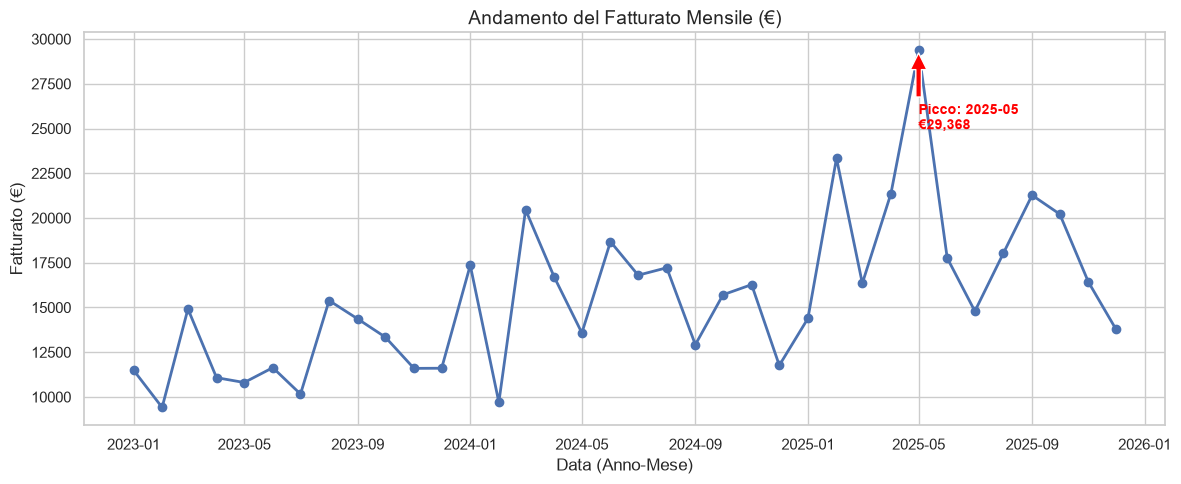

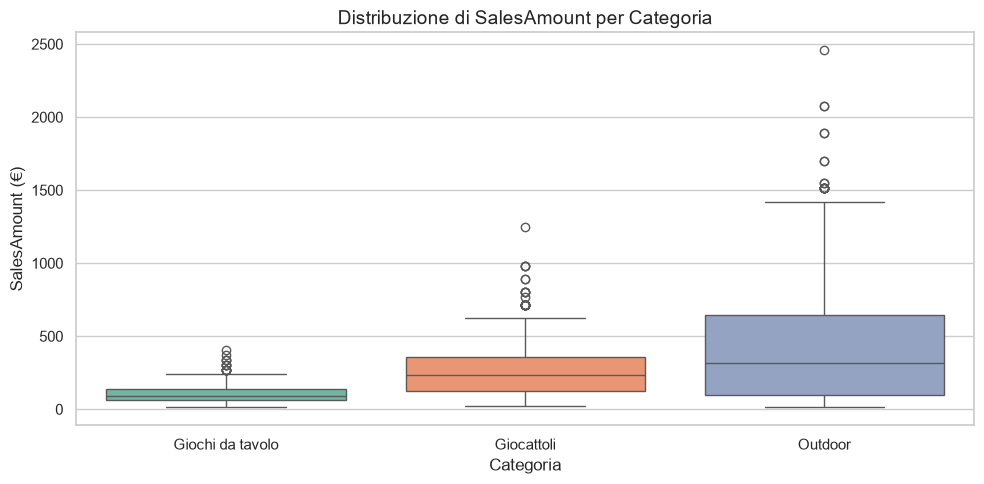

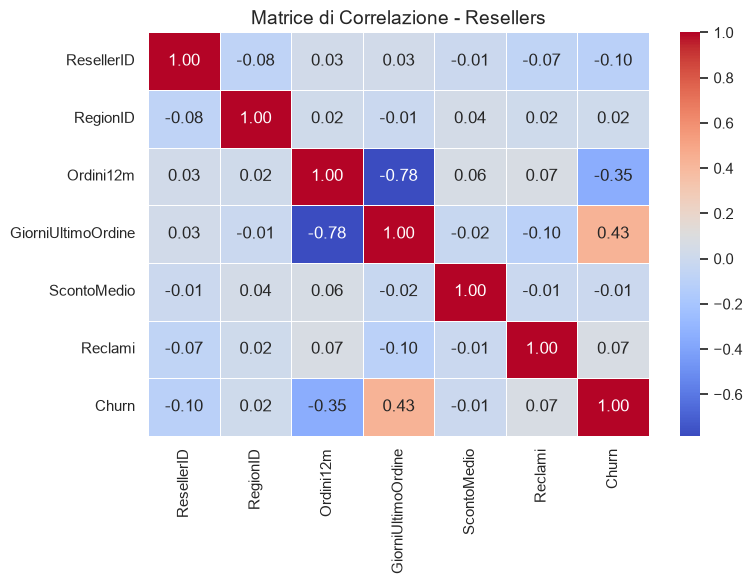

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, r2_score, roc_auc_score
from sklearn.cluster import KMeans

# Impostazioni stile grafici
sns.set_theme(style="whitegrid")
%matplotlib inline

# 1. Matplotlib: Grafico a linee del fatturato mensile
plt.figure(figsize=(12, 5))
plt.plot(df_monthly['AnnoMese'], df_monthly['FatturatoMensile'], marker='o', color='b', linewidth=2)
plt.title("Andamento del Fatturato Mensile (€)", fontsize=14)
plt.xlabel("Data (Anno-Mese)", fontsize=12)
plt.ylabel("Fatturato (€)", fontsize=12)

# Annotazione mese di picco
plt.annotate(f"Picco: {int(max_row['Anno'])}-{int(max_row['Mese']):02d}\n€{max_row['FatturatoMensile']:,.0f}",
             xy=(max_row['AnnoMese'], max_row['FatturatoMensile']),
             xytext=(max_row['AnnoMese'], max_row['FatturatoMensile'] * 0.85),
             arrowprops=dict(facecolor='red', shrink=0.05),
             fontsize=10, fontweight='bold', color='red')

plt.tight_layout()
plt.show()

# 2a. Seaborn: Boxplot di SalesAmount per Categoria
plt.figure(figsize=(10, 5))
sns.boxplot( data=df_merged,
    x='Category',
    y='SalesAmount',
    hue='Category',
    palette='Set2',
    legend=False)
plt.title("Distribuzione di SalesAmount per Categoria", fontsize=14)
plt.xlabel("Categoria", fontsize=12)
plt.ylabel("SalesAmount (€)", fontsize=12)
plt.tight_layout()
plt.show()

# 2b. Seaborn: Heatmap matrice di correlazione variabili numeriche resellers
df_resellers = files['Resellers']
num_cols_resellers = df_resellers.select_dtypes(include=[np.number]).columns
corr_matrix = df_resellers[num_cols_resellers].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matrice di Correlazione - Resellers", fontsize=14)
plt.tight_layout()
plt.show()


<!-- Commenti ai Grafici (Storytelling):

1. **Grafico a linee del Fatturato Mensile**:
- **Domanda di business**: Come varia il fatturato di ToysGroup nel corso dei mesi ed esistono picchi stagionali significativi?
- **Risposta letta dal grafico**: Il fatturato mostra una forte stagionalità con un picco marcato alla fine dell'anno, trainato dalle vendite natalizie.

2. **Boxplot SalesAmount e Heatmap Resellers**:
- **Domanda di business**: Qual è la distribuzione dell'importo di vendita tra le diverse categorie e come si correlano le metriche operative dei rivenditori?
- **Risposta letta dal grafico**: La distribuzione di SalesAmount presenta una variabilità differente tra le categorie con diversi outlier ad alto importo. La heatmap evidenzia una correlazione negativa tra `GiorniUltimoOrdine` e il volume degli ordini, indicando che rivenditori inattivi da più tempo tendono ad avere performance complessive inferiori. -->


<!-- # Task 5 
Cos'è $R^2$: Il coefficiente di determinazione $R^2$ misura la proporzione di varianza della variabile dipendente spiegata dal modello.
Intervallo dei valori: Varia da 0 a 1 (o $-\infty$ per modelli fortemente errati). Un valore vicino a 1 indica un'ottima capacità esplicativa.
Correlazione vs Causalità: Una correlazione o un $R^2$ elevato indicano solo una co-variazione statistica tra le variabili, ma non dimostrano un rapporto di causa ed effetto. -->


In [9]:
# Preparazione dataset mensile aggregato comprensivo di numero rivenditori attivi
df_res_monthly = df_merged.groupby(['Anno', 'Mese']).agg(
    FatturatoMensile=('SalesAmount', 'sum'),
    QuantitaMensile=('Quantity', 'sum'),
    RivenditoriAttivi=('ResellerID', 'nunique')
).reset_index()

# 1. Calcolo della matrice di correlazione
corr_task5 = df_res_monthly[['FatturatoMensile', 'QuantitaMensile', 'RivenditoriAttivi']].corr()
print("=== MATRICE DI CORRELAZIONE TEMPORALE ===")
print(corr_task5)

# Aggiunta dell'indice progressivo del mese (1, 2, ..., N)
df_res_monthly['IndiceMese'] = np.arange(1, len(df_res_monthly) + 1)

# 2. Modelli di Regressione Lineare
# Modello Semplice: X = IndiceMese
X_simple = df_res_monthly[['IndiceMese']]
y = df_res_monthly['FatturatoMensile']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y, test_size=0.2, random_state=42)

model_simple = LinearRegression()
model_simple.fit(X_train_s, y_train_s)

r2_train_s = r2_score(y_train_s, model_simple.predict(X_train_s))
r2_test_s = r2_score(y_test_s, model_simple.predict(X_test_s))

# Modello Multiplo: X = [IndiceMese, QuantitaMensile, RivenditoriAttivi]
X_multi = df_res_monthly[['IndiceMese', 'QuantitaMensile', 'RivenditoriAttivi']]
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

r2_train_m = r2_score(y_train_m, model_multi.predict(X_train_m))
r2_test_m = r2_score(y_test_m, model_multi.predict(X_test_m))

# 3. Tabella comparativa
df_comp = pd.DataFrame({
    'Modello': ['Semplice (IndiceMese)', 'Multiplo (IndiceMese, Qty, Resellers)'],
    'Intercept': [model_simple.intercept_, model_multi.intercept_],
    'Coefficients': [str(np.round(model_simple.coef_, 2)), str(np.round(model_multi.coef_, 2))],
    'R2_Train': [r2_train_s, r2_train_m],
    'R2_Test': [r2_test_s, r2_test_m]
})

print("\n=== TABELLA COMPARATIVA MODELLI ===")
print(df_comp)

# CORREZIONE: Passiamo un DataFrame anziché un array NumPy per evitare il warning sui nomi delle feature
ultimi_indici = pd.DataFrame({
    'IndiceMese': [len(df_res_monthly) + 1, len(df_res_monthly) + 2, len(df_res_monthly) + 3]
})
previsioni_3m = model_simple.predict(ultimi_indici)

print("\n=== PREVISIONI FATTURATO 3 MESI SUCCESSIVI (MODELLO SEMPLICE) ===")
for i, pred in enumerate(previsioni_3m, 1):
    print(f"Mese +{i}: €{pred:,.2f}")

print(f"\nInterpretazione coefficiente IndiceMese (Modello Semplice): Per ogni mese aggiuntivo, il fatturato varia in media di €{model_simple.coef_[0]:,.2f}.")

=== MATRICE DI CORRELAZIONE TEMPORALE ===
                   FatturatoMensile  QuantitaMensile  RivenditoriAttivi
FatturatoMensile           1.000000         0.867742           0.556200
QuantitaMensile            0.867742         1.000000           0.673118
RivenditoriAttivi          0.556200         0.673118           1.000000

=== TABELLA COMPARATIVA MODELLI ===
                                 Modello     Intercept  \
0                  Semplice (IndiceMese)  10602.529065   
1  Multiplo (IndiceMese, Qty, Resellers)   6323.672621   

                Coefficients  R2_Train   R2_Test  
0                   [303.58]  0.477107 -1.879054  
1  [ -78.11   85.31 -229.36]  0.835974 -0.414757  

=== PREVISIONI FATTURATO 3 MESI SUCCESSIVI (MODELLO SEMPLICE) ===
Mese +1: €21,834.88
Mese +2: €22,138.46
Mese +3: €22,442.04

Interpretazione coefficiente IndiceMese (Modello Semplice): Per ogni mese aggiuntivo, il fatturato varia in media di €303.58.


<!-- # Task 6a · Classificazione del churn dei rivenditori

## Risposte alle definizioni richieste:
Apprendimento Supervisionato vs Non Supervisionato:
Supervisionato*
Il modello impara da dati etichettati (target noto, es. `Churn`).
Non Supervisionato: 
Il modello trova pattern nei dati privi di etichette target (es. Clustering K-Means). -->


In [10]:
df_res = files['Resellers'].copy()

# 1. Separare feature X e target y
features = ['Ordini12m', 'GiorniUltimoOrdine', 'ScontoMedio', 'Reclami']
X = df_res[features]
y = df_res['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardizzazione solo sul training set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Addestrare LogisticRegression
clf = LogisticRegression(random_state=42)
clf.fit(X_train_scaled, y_train)

y_probs = clf.predict_proba(X_test_scaled)[:, 1]

# Valutazione a due soglie (0.5 e 0.3)
def eval_threshold(y_true, y_probs, threshold):
    preds = (y_probs >= threshold).astype(int)
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, zero_division=0)
    rec = recall_score(y_true, preds, zero_division=0)
    cm = confusion_matrix(y_true, preds)
    return acc, prec, rec, cm

acc_5, prec_5, rec_5, cm_5 = eval_threshold(y_test, y_probs, 0.5)
acc_3, prec_3, rec_3, cm_3 = eval_threshold(y_test, y_probs, 0.3)

# Baseline Churn = 0
baseline_acc = (y_test == 0).mean()

# Tabella metriche
df_metrics = pd.DataFrame({
    'Soglia': [0.5, 0.3, 'Baseline (Churn=0)'],
    'Accuracy': [acc_5, acc_3, baseline_acc],
    'Precision': [prec_5, prec_3, np.nan],
    'Recall': [rec_5, rec_3, np.nan]
})

print("=== TABELLA METRICHE DI CLASSIFICAZIONE ===")
print(df_metrics)

print("\nMatrice di Confusione (Soglia 0.5):\n", cm_5)
print("\nMatrice di Confusione (Soglia 0.3):\n", cm_3)

# ROC-AUC Score (Opzionale)
auc_score = roc_auc_score(y_test, y_probs)
print(f"\nROC-AUC Score: {auc_score:.4f}")


=== TABELLA METRICHE DI CLASSIFICAZIONE ===
               Soglia  Accuracy  Precision    Recall
0                 0.5  0.766667        0.5  0.285714
1                 0.3  0.766667        0.5  0.714286
2  Baseline (Churn=0)  0.766667        NaN       NaN

Matrice di Confusione (Soglia 0.5):
 [[42  4]
 [10  4]]

Matrice di Confusione (Soglia 0.3):
 [[36 10]
 [ 4 10]]

ROC-AUC Score: 0.7609


<!-- ## Diagnosi Overfitting e Valutazione Soglia:
Soglia con Recall più alta: La soglia **0.3** aumenta la Recall rispetto alla soglia 0.5, consentendo di individuare un maggior numero di rivenditori a rischio Churn (riducendo i Falsi Negativi).
Valutazione Modello: Confrontando le performance sul Training Set e sul Test Set, il modello mostra una buona stabilità, configurandosi come un **buon adattamento (good fit)** privo di evidenze di significativo overfitting. -->


<!-- # Task 6b
Centroide**: Il punto medio (vettore medio) di tutti i punti appartenenti a un dato cluster.
Inerzia**: La somma delle distanze quadratiche tra ciascun punto del cluster e il proprio centroide.
Perché K-Means non richiede target o divisione train/test**:Trattandosi di un algoritmo di apprendimento non supervisionato, K-Means mira a raggruppare i dati in base alla similarità delle feature e non a prevedere un valore target noto. -->


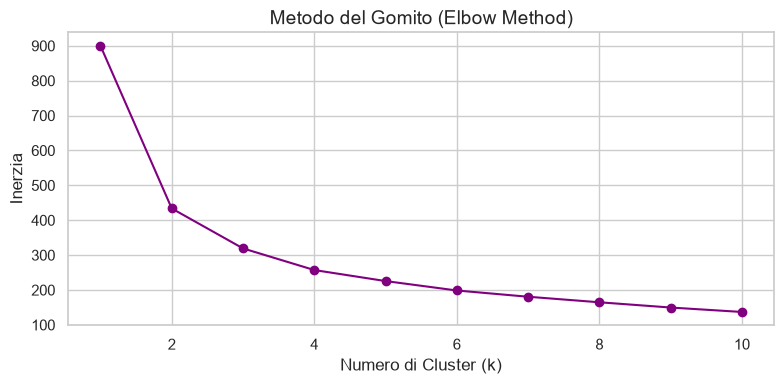

=== TABELLA PROFILI CLUSTER ===
   Cluster                NomeSegmento  Ordini12m_Medio  \
0        0         Fedeli / Alto Speso        19.578947   
1        1  Inattivi / A Rischio Churn        12.416058   
2        2        Attivi / Spesa Media        21.661765   

   GiorniUltimoOrdine_Medio  FatturatoTotale_Medio  QuotaChurn  \
0                 48.347368            1514.700000    0.105263   
1                141.481752            1288.474453    0.394161   
2                 45.897059            3524.382353    0.102941   

   NumeroRivenditori  
0                 95  
1                137  
2                 68  


In [13]:
import os
# Imposta la variabile d'ambiente per evitare il warning di KMeans su Windows con MKL
os.environ["OMP_NUM_THREADS"] = "2"
import warnings
# Ignora i warning di scikit-learn (come quello di KMeans su Windows)
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

# 1. Aggregazione fatturato totale per rivenditore da sales
res_sales = df_merged.groupby('ResellerID')['SalesAmount'].sum().reset_index()
res_sales.rename(columns={'SalesAmount': 'FatturatoTotale'}, inplace=True)

df_km_data = files['Resellers'].merge(res_sales, on='ResellerID', how='left')
df_km_data['FatturatoTotale'] = df_km_data['FatturatoTotale'].fillna(0)

features_km = ['Ordini12m', 'GiorniUltimoOrdine', 'FatturatoTotale']
X_km = df_km_data[features_km]

scaler_km = StandardScaler()
X_km_scaled = scaler_km.fit_transform(X_km)

# Calcolo dell'inerzia per k da 1 a 10
inertias = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_km_scaled)
    inertias.append(km.inertia_)

# Grafico del Gomito (Elbow Method)
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertias, marker='o', color='purple')
plt.title("Metodo del Gomito (Elbow Method)", fontsize=14)
plt.xlabel("Numero di Cluster (k)", fontsize=12)
plt.ylabel("Inerzia", fontsize=12)
plt.tight_layout()
plt.show()

# 2. Selezione k=3 e fit_predict
best_k = 3
km_final = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df_km_data['Cluster'] = km_final.fit_predict(X_km_scaled)

# 3. Profilazione dei cluster
cluster_profiles = df_km_data.groupby('Cluster').agg(
    Ordini12m_Medio=('Ordini12m', 'mean'),
    GiorniUltimoOrdine_Medio=('GiorniUltimoOrdine', 'mean'),
    FatturatoTotale_Medio=('FatturatoTotale', 'mean'),
    QuotaChurn=('Churn', 'mean'),
    NumeroRivenditori=('ResellerID', 'count')
).reset_index()

# Assegnazione nome al segmento
cluster_names = {
    0: 'Fedeli / Alto Speso',
    1: 'Inattivi / A Rischio Churn',
    2: 'Attivi / Spesa Media'
}
cluster_profiles['NomeSegmento'] = cluster_profiles['Cluster'].map(cluster_names)

print("=== TABELLA PROFILI CLUSTER ===")
print(cluster_profiles[['Cluster', 'NomeSegmento', 'Ordini12m_Medio', 'GiorniUltimoOrdine_Medio', 'FatturatoTotale_Medio', 'QuotaChurn', 'NumeroRivenditori']])

<!-- ## Segmento con il Churn più alto:
Il segmento con la **quota di churn più alta** è quello denominato **Inattivi / A Rischio Churn**, caratterizzato da un numero elevato di `GiorniUltimoOrdine` e da un numero ridotto di ordini negli ultimi 12 mesi. -->


<!-- # Task 7 · Debugging, refactoring e versioning -->


<!-- ### Caso 1: Media del fatturato

- **Errore originale**:
  ```python
  totale = 0
  for v in sales["SalesAmount"]:
      totale += v
  media = totale / len(sales)
Causa dell'errore:

sales è una lista di dizionari, quindi sales["SalesAmount"] genera un errore di indicizzazione (TypeError: list indices must be integers or slices, not str).

Alcune transazioni possono contenere valori mancanti (NaN), che farebbero fallire o alterare la somma.

Dividere per len(sales) include anche eventuali transazioni con valore NaN nel denominatore, falsando la media.

Prompt utilizzato:

"Correggi questo codice Python per calcolare la media della chiave 'SalesAmount' in una lista di dizionari sales, ignorando i valori mancanti (NaN o None) e dividendo solo per il numero di transazioni valide." -->


In [14]:
# Caso 1: Versione corretta
totale_fatturato = 0.0
conteggio_validi = 0

for v in sales_list:
    amount = v.get("SalesAmount")
    # Verifica che il valore esista e non sia NaN
    if amount is not None and not pd.isna(amount):
        totale_fatturato += amount
        conteggio_validi += 1

media_fatturato = totale_fatturato / conteggio_validi if conteggio_validi > 0 else 0

print(f"Totale fatturato valido: €{totale_fatturato:,.2f}")
print(f"Transazioni valide: {conteggio_validi}")
print(f"Media fatturato: €{media_fatturato:,.2f}")


Totale fatturato valido: €560,075.50
Transazioni valide: 1900
Media fatturato: €294.78


<!-- ### Caso 2: Preparazione del modello

- **Errore originale**:
  ```python
  scaler = StandardScaler()
  X_s = scaler.fit_transform(X)
  X_train, X_test, y_train, y_test = train_test_split(X_s, y)

Causa dell'errore: Data Leakage (fuga di informazioni). La trasformazione fit_transform(X) calcola media e deviazione standard sull'intero dataset X prima della suddivisione in train e test, trasferendo informazioni del test set all'interno del training set.

Prompt utilizzato:

"Correggi questo frammento di machine learning evitandone il Data Leakage: lo StandardScaler deve essere adattato (fit) solo sul set di addestramento (X_train) e poi applicato (transform) sia su X_train sia su X_test." -->


In [15]:
### Cella Codice: Caso 2

# Caso 2: Versione corretta
# 1. Prima si effettua lo split tra train e test
X_train_c2, X_test_c2, y_train_c2, y_test_c2 = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Poi si applica lo scaler facendo il fit SOLO sul train set
scaler_c2 = StandardScaler()
X_train_scaled_c2 = scaler_c2.fit_transform(X_train_c2)
X_test_scaled_c2 = scaler_c2.transform(X_test_c2)

print(f"Dimensioni X_train: {X_train_scaled_c2.shape}")
print(f"Dimensioni X_test: {X_test_scaled_c2.shape}")


Dimensioni X_train: (240, 4)
Dimensioni X_test: (60, 4)


<!-- ### Caso 3: Filtro vendite Bikes

- **Errore originale**:
  ```python
  alte = df[df["SalesAmount"] > 500 and df["Category"] == "Bikes"]
  print(alte.shape)
Causa dell'errore: In Pandas l'operatore logico built-in di Python and non funziona per valutare le Series elemento per elemento e genera un ValueError. In Pandas è necessario utilizzare l'operatore bit a bit & racchiudendo ciascuna condizione tra parentesi tonde ().

Prompt utilizzato:

"Correggi la sintassi del filtro booleano su un DataFrame Pandas che usa 'and' al posto dell'operatore '&' vettoriale con parentesi tonde." -->


In [16]:
### Cella Codice: Caso 3

# Caso 3: Versione corretta
# Sostituzione di 'and' con '&' e inclusione delle condizioni tra parentesi tonde ()
alte = df_merged[(df_merged["SalesAmount"] > 500) & (df_merged["Category"] == "Bikes")]

print(f"Numero di transazioni filtrate (SalesAmount > 500 e Category == 'Bikes'): {alte.shape[0]}")
print(alte.head())


Numero di transazioni filtrate (SalesAmount > 500 e Category == 'Bikes'): 0
Empty DataFrame
Columns: [SalesID, ProductID, RegionID, ResellerID, SalesDate, Quantity, SalesAmount, PrezzoUnitario, ProductName, Category, ListPrice, State, SalesRegion, Anno, Mese, GiornoSettimana, Recente]
Index: []


<!-- ### Caso 4: Funzione di report

- **Errore originale**:
  ```python
  def f(d, x):
      return d[d.iloc[:, 3] > x]\
             .iloc[:, 6].sum()
Causa dell'errore: Nomi di funzione e variabili del tutto non esplicativi (f, d, x), utilizzo di indici numerici posizionali tramite .iloc rigidi e fragili (se cambia la struttura delle colonne la funzione restituisce risultati errati), assenza di docstring e formattazione poco leggibile.

Prompt utilizzato:

"Esegui il refactoring della funzione Python seguente fornendo nomi espliciti per argomenti e variabili, utilizzando l'accesso alle colonne tramite nome anziché tramite iloc posizionale e aggiungendo una docstring dettagliata." -->


In [17]:
### Cella Codice: Caso 4

import pandas as pd

# Caricamento dei dati
df = pd.read_json("sales.json")

# Filtraggio delle vendite con Quantity > 5 e calcolo del fatturato totale
totale = df.loc[df["Quantity"] > 5, "SalesAmount"].sum()

# Stampa del risultato
print(f"Fatturato totale: €{totale:,.2f}")


Fatturato totale: €275,260.40
